# Tarea raster · 3. ¿Cuánto y qué se quemó en Livitaca y Huanoquite?

Paso 6 del método del profesor (Sentinel-2 y dNBR) y el cruce con cobertura, personas y
viviendas, para dos incendios en territorio de **comunidades campesinas quechuas** del Cusco:

| Incendio | Provincia | Fuego (VIIRS) | Por qué este |
|---|---|---|---|
| **Livitaca** | Chumbivilcas | 15 oct | Imágenes con 0 % de nubes antes (7 oct) y después (17 oct) |
| **Huanoquite** | Paruro | 14–17 oct | El incendio más grande del Cusco esa semana; 0 % de nubes el 17 oct |

**Por qué no Río Tambo, Manantay o Yarinacocha:** en la selva es temporada de lluvias. Después
del fuego, la mejor combinación de imágenes deja ver solo el 33 % de Río Tambo, y en Pucallpa
las nubes cubren entre 56 % y 99 % (revisión en la bitácora del README).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import rioxarray
from scipy import ndimage
from shapely import contains_xy

from comun import PROC, FIG, STAC, CRS_METRICO

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
catalogo = pystac_client.Client.open(STAC, modifier=planetary_computer.sign_inplace)

## Los dos incendios

Tomamos los focos limpios del notebook 2. Cada incendio se identifica por su número de grupo.

In [2]:
focos = gpd.read_file(PROC / "focos_limpios.gpkg")
incendios = gpd.read_file(PROC / "incendios_100ha_zona5km.gpkg").set_index("incendio")

CASOS = {
    # "antes" es una lista en orden de preferencia: si una fecha tiene nubes, se rellena con la siguiente
    "Livitaca":   {"incendio": 166, "antes": ["2026-10-07"], "despues": "2026-10-17"},
    "Huanoquite": {"incendio": 12,  "antes": ["2026-10-10", "2026-10-07", "2026-10-05"], "despues": "2026-10-17"},
}
for nombre, caso in CASOS.items():
    fila = incendios.loc[caso["incendio"]]
    caso["focos"] = focos[focos.incendio == caso["incendio"]].to_crs(CRS_METRICO)
    print(f"{nombre:11s} {fila.distrito}, {fila.provincia}: {fila.focos} focos, huella VIIRS {fila.huella_ha:.0f} ha, "
          f"{fila.inicio[:10]} a {fila.ultimo[:10]}")

Livitaca    LIVITACA, CHUMBIVILCAS: 28 focos, huella VIIRS 267 ha, 2026-10-15 a 2026-10-15
Huanoquite  HUANOQUITE, PARURO: 80 focos, huella VIIRS 647 ha, 2026-10-14 a 2026-10-17


## Paso 6 · Sentinel-2: elegir las imágenes

Para cada fecha buscamos la escena que cubre la zona y medimos las nubes **dentro de la zona del
incendio** (no en toda la escena de 110 × 110 km, que es lo que reporta el catálogo).

**Compuesto multitemporal.** Las nubes se mueven y el paisaje antes del fuego casi no cambia en
una o dos semanas. Si la imagen preferida tiene nubes sobre un píxel, ese píxel se toma de la
siguiente fecha despejada. Así se reconstruye la imagen "antes" de Huanoquite (10/10 tenía nubes
sobre el incendio; 7/10 y 5/10 estaban despejadas).

La capa SCL clasifica cada píxel. Consideramos no válidos: 0 sin dato, 3 sombra de nube,
6 agua, 8–9 nube, 10 cirro.

In [3]:
NO_VALIDO = [0, 3, 6, 8, 9, 10]


def escena(caja_4326, fecha):
    """La escena Sentinel-2 L2A de esa fecha que cubre la caja (si hay dos teselas, la más completa)."""
    items = catalogo.search(collections=["sentinel-2-l2a"], intersects=caja_4326, datetime=fecha).item_collection()
    mejor, cobertura = None, -1
    for it in items:
        scl = recortar(it, "SCL", caja_4326)
        cub = float((scl > 0).mean())
        if cub > cobertura:
            mejor, cobertura = it, cub
    return mejor


def recortar(item, banda, caja_4326, ref=None):
    da = rioxarray.open_rasterio(item.assets[banda].href).squeeze(drop=True)
    caja = gpd.GeoSeries([caja_4326], crs=4326).to_crs(da.rio.crs).total_bounds
    da = da.rio.clip_box(*caja)
    return da if ref is None else da.rio.reproject_match(ref)


def reflectancia(item, banda, caja, ref):
    """Valores digitales → reflectancia. Desde la línea base 04.00 (2022) L2A suma 1000 a cada valor."""
    dn = recortar(item, banda, caja, ref).astype("float32")
    offset = -1000 if float(item.properties.get("s2:processing_baseline", "0")) >= 4 else 0
    return (dn + offset) / 10000


for nombre, caso in CASOS.items():
    zona = caso["focos"].buffer(4000).union_all().envelope          # caja de trabajo: focos + 4 km
    caso["caja"] = gpd.GeoSeries([zona], crs=CRS_METRICO).to_crs(4326).iloc[0]
    caso["items_antes"] = [escena(caso["caja"], f) for f in caso["antes"]]
    caso["item_despues"] = escena(caso["caja"], caso["despues"])
    for it in caso["items_antes"] + [caso["item_despues"]]:
        scl = recortar(it, "SCL", caso["caja"])
        nubes = float(np.isin(scl, [3, 8, 9, 10]).sum() / (scl > 0).sum())
        print(f"{nombre:11s} {it.datetime:%Y-%m-%d}  {it.id}  nubes en la zona: {nubes:.1%}")

Livitaca    2026-10-07  S2A_MSIL2A_20261007T145941_R039_T19LBE_20261007T224605  nubes en la zona: 0.0%


Livitaca    2026-10-17  S2A_MSIL2A_20261017T145731_R039_T19LBE_20261018T001002  nubes en la zona: 0.0%


Huanoquite  2026-10-10  S2B_MSIL2A_20261010T145729_R039_T18LZK_20261010T200116  nubes en la zona: 27.9%


Huanoquite  2026-10-07  S2A_MSIL2A_20261007T145941_R039_T18LZK_20261007T224605  nubes en la zona: 4.3%


Huanoquite  2026-10-05  S2C_MSIL2A_20261005T145731_R039_T18LZK_20261005T175220  nubes en la zona: 0.0%


Huanoquite  2026-10-17  S2A_MSIL2A_20261017T145731_R039_T18LZK_20261018T001002  nubes en la zona: 0.2%


## NBR y dNBR

- **NBR** = (NIR − SWIR) / (NIR + SWIR). La vegetación sana refleja mucho infrarrojo cercano
  (B8A) y poco de onda corta (B12). Lo quemado, al revés.
- **dNBR** = NBR antes − NBR después. Positivo = la vegetación perdió vigor (quema).
- Usamos **B8A y B12**, ambas de 20 m: no hay que remuestrear una banda a la otra.

Clases de severidad del USGS (Key y Benson, 2006), las más citadas:

| dNBR | Clase |
|---|---|
| < 0,10 | No quemado |
| 0,10 – 0,27 | Baja |
| 0,27 – 0,44 | Moderada-baja |
| 0,44 – 0,66 | Moderada-alta |
| ≥ 0,66 | Alta |

**Decisión: dNBR sembrado con focos** (el método del tablero del profesor). Quemado = dNBR ≥ 0,27
(el umbral de la diapositiva de Curahuasi), pero solo las **manchas continuas que tocan a ≤ 1 km
algún foco VIIRS** del incendio. Así:

- no se suman cambios lejanos que no son este incendio (cosechas, riberas, otra quema);
- sí se incluye la parte de la cicatriz que VIIRS no vio (se quemó entre dos pasadas del satélite).

Una primera versión usaba solo "≤ 1 km de focos" y cortaba la cicatriz de Livitaca por el sur:
el mapa lo mostró. Por eso queda como variante en la tabla de sensibilidad.

In [4]:
CORTES = [0.10, 0.27, 0.44, 0.66]
CLASES = ["Baja", "Moderada-baja", "Moderada-alta", "Alta"]
HA_PIXEL = 20 * 20 / 1e4                                           # 0,04 ha

for nombre, caso in CASOS.items():
    ref = recortar(caso["item_despues"], "B12", caso["caja"])
    def nbr(it):
        nir, swir = reflectancia(it, "B8A", caso["caja"], ref), reflectancia(it, "B12", caso["caja"], ref)
        scl = recortar(it, "SCL", caso["caja"], ref)
        return ((nir - swir) / (nir + swir)).where(~np.isin(scl, NO_VALIDO))

    antes = nbr(caso["items_antes"][0])
    for it in caso["items_antes"][1:]:
        antes = antes.fillna(nbr(it))                              # compuesto: rellena nubes con la siguiente fecha
    dnbr = (antes - nbr(caso["item_despues"])).rio.write_crs(ref.rio.crs)

    # semillas: ≤ 1 km de algún foco del incendio
    cerca = caso["focos"].to_crs(ref.rio.crs).buffer(1000).union_all()
    xx, yy = np.meshgrid(dnbr.x.values, dnbr.y.values)
    caso["cerca"] = contains_xy(cerca, xx, yy)

    def sembrar(umbral):
        """Manchas continuas (8 vecinos) de dNBR ≥ umbral que tocan una semilla."""
        manchas, _ = ndimage.label(dnbr.values >= umbral, structure=np.ones((3, 3)))
        return np.isin(manchas, np.setdiff1d(np.unique(manchas[caso["cerca"]]), [0]))

    caso["zona"] = sembrar(0.27)                                    # cifra conservadora
    caso["zona_amplia"] = sembrar(0.10)                             # incluye quema leve (pastizal seco)
    caso["dnbr"], caso["ref"] = dnbr, ref
    dnbr.rio.to_raster(PROC / f"dnbr_{nombre.lower()}.tif")

    # severidad: dentro del área quemada + el anillo de severidad baja que la rodea (≤ 1 km de focos)
    v = dnbr.values[caso["zona"] | caso["cerca"]]
    invalido = np.isnan(dnbr.values[caso["cerca"]]).mean()
    filas = {c: np.sum((v >= lo) & (v < hi)) * HA_PIXEL
             for c, lo, hi in zip(CLASES, CORTES, CORTES[1:] + [9])}
    caso["severidad_ha"] = pd.Series(filas)
    caso["quemado_ha"] = caso["zona"].sum() * HA_PIXEL
    caso["quemado_amplio_ha"] = caso["zona_amplia"].sum() * HA_PIXEL
    caso["sin_dato"] = invalido
    print(f"\n{nombre}: {caso['quemado_ha']:,.0f} ha (dNBR ≥ 0,27) a {caso['quemado_amplio_ha']:,.0f} ha (dNBR ≥ 0,10), "
          f"sembrado con focos · "
          f"píxeles sin dato en la zona: {invalido:.1%}")
    print(caso["severidad_ha"].round(0).to_string())


Livitaca: 425 ha (dNBR ≥ 0,27) a 929 ha (dNBR ≥ 0,10), sembrado con focos · píxeles sin dato en la zona: 0.0%
Baja             241.0
Moderada-baja    312.0
Moderada-alta    113.0
Alta               0.0



Huanoquite: 409 ha (dNBR ≥ 0,27) a 895 ha (dNBR ≥ 0,10), sembrado con focos · píxeles sin dato en la zona: 0.0%
Baja             472.0
Moderada-baja    313.0
Moderada-alta     95.0
Alta               1.0


### ¿Cuánto cambia el número según la decisión?

Como en Curahuasi: la computadora siempre da un número. Mostramos tres variantes para que se
vea qué tan sensible es el resultado.

In [5]:
sens = {}
for nombre, caso in CASOS.items():
    d = caso["dnbr"].values
    sens[nombre] = {
        "≥ 0,27 · sembrado con focos (cifra conservadora)": caso["quemado_ha"],
        "≥ 0,10 · sembrado con focos (cifra amplia)": caso["quemado_amplio_ha"],
        "≥ 0,27 · solo ≤ 1 km de focos": np.nansum(d[caso["cerca"]] >= 0.27) * HA_PIXEL,
        "≥ 0,10 · ≤ 1 km de focos": np.nansum(d[caso["cerca"]] >= 0.10) * HA_PIXEL,
        "≥ 0,44 · ≤ 1 km de focos": np.nansum(d[caso["cerca"]] >= 0.44) * HA_PIXEL,
        "≥ 0,27 · toda la caja (focos + 4 km)": np.nansum(d >= 0.27) * HA_PIXEL,
        "huella VIIRS (píxeles de 375 m)": incendios.loc[caso["incendio"], "huella_ha"],
    }
sensibilidad = pd.DataFrame(sens).round(0)
sensibilidad

,Livitaca,Huanoquite
"≥ 0,27 · sembrado con focos (cifra conservadora)",425.0,409.0
"≥ 0,10 · sembrado con focos (cifra amplia)",929.0,895.0
"≥ 0,27 · solo ≤ 1 km de focos",305.0,403.0
"≥ 0,10 · ≤ 1 km de focos",546.0,876.0
"≥ 0,44 · ≤ 1 km de focos",90.0,96.0
"≥ 0,27 · toda la caja (focos + 4 km)",488.0,421.0
huella VIIRS (píxeles de 375 m),267.0,647.0


## Mapas

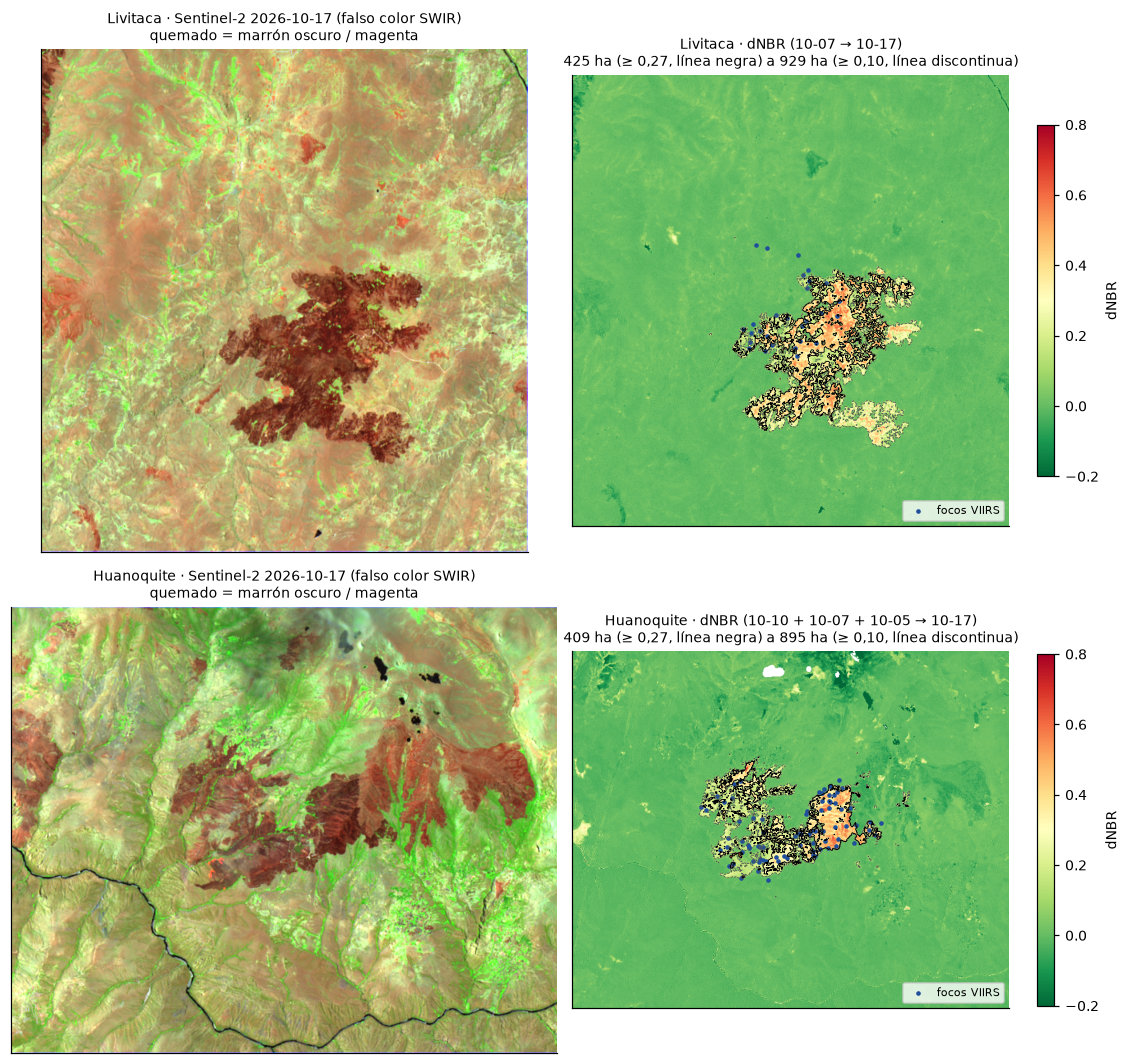

In [6]:
fig, ejes = plt.subplots(2, 2, figsize=(10.5, 10))
for (nombre, caso), (izq, der) in zip(CASOS.items(), ejes):
    it = caso["item_despues"]
    rgb = np.dstack([reflectancia(it, b, caso["caja"], caso["ref"]).values for b in ("B12", "B8A", "B04")])
    ext = [float(caso["ref"].x.min()), float(caso["ref"].x.max()), float(caso["ref"].y.min()), float(caso["ref"].y.max())]
    izq.imshow(np.clip(rgb / 0.35, 0, 1), extent=ext)
    izq.set_title(f"{nombre} · Sentinel-2 {caso['despues']} (falso color SWIR)\nquemado = marrón oscuro / magenta", fontsize=9)
    im = der.imshow(caso["dnbr"].values, cmap="RdYlGn_r", vmin=-0.2, vmax=0.8, extent=ext)
    der.contour(caso["dnbr"].x, caso["dnbr"].y, caso["zona_amplia"].astype(float), levels=[0.5],
                colors="#555", linewidths=0.5, linestyles="dashed")
    der.contour(caso["dnbr"].x, caso["dnbr"].y, caso["zona"].astype(float), levels=[0.5], colors="black", linewidths=0.6)
    foc = caso["focos"].to_crs(caso["ref"].rio.crs)
    der.scatter(foc.geometry.x, foc.geometry.y, s=4, c="#1f4e9c", label="focos VIIRS")
    der.set_title(f"{nombre} · dNBR ({' + '.join(f[5:] for f in caso['antes'])} → {caso['despues'][5:]})\n"
                  f"{caso['quemado_ha']:,.0f} ha (≥ 0,27, línea negra) a {caso['quemado_amplio_ha']:,.0f} ha (≥ 0,10, línea discontinua)",
                  fontsize=9)
    der.legend(loc="lower right", fontsize=7)
    plt.colorbar(im, ax=der, shrink=0.7, label="dNBR")
    for ax in (izq, der):
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); fig.savefig(FIG / "03_dnbr_livitaca_huanoquite.png", dpi=150); plt.show()

## Paso 3 aplicado · ¿Qué se quemó?

Cruzamos los píxeles quemados con ESA WorldCover 2021 (10 m), llevado a la grilla de 20 m del
dNBR con vecino más cercano (es una variable de categorías: no se promedia).

**Por qué dos cifras.** El dNBR mide cuánto verde se perdió. El bosque parte de un NBR alto y,
al quemarse, cae mucho. El pastizal de puna en octubre ya está seco: parte de un NBR bajo y, aunque
se queme por completo, la caída es pequeña. El umbral 0,27 (USGS, calibrado en bosques) deja
fuera parte de esa quema. Por eso cada incendio se reporta como un **rango**: de ≥ 0,27
(conservador) a ≥ 0,10 (incluye quema leve, con más riesgo de confundir pasto que solo se secó).
Y en cada cifra se separa **qué parte es pastizal y qué parte es bosque**.

In [7]:
CLASES_WC = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Urbano",
             60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar", 100: "Musgo"}
from rasterio.enums import Resampling

filas = []
for nombre, caso in CASOS.items():
    items = catalogo.search(collections=["esa-worldcover"], intersects=caso["caja"]).item_collection()
    wc = recortar(items[0], "map", caso["caja"]).rio.reproject_match(caso["ref"], resampling=Resampling.nearest)
    caso["wc"] = wc
    for cifra, zona in (("conservadora (≥ 0,27)", caso["zona"]), ("amplia (≥ 0,10)", caso["zona_amplia"])):
        ha = pd.Series(wc.values[zona]).map(CLASES_WC).value_counts() * HA_PIXEL
        for cobertura, h in ha.items():
            filas.append({"incendio": nombre, "cifra": cifra, "cobertura": cobertura, "ha": h})
que_se_quemo = (pd.DataFrame(filas).pivot_table(index=["incendio", "cobertura"], columns="cifra", values="ha", fill_value=0)
                [["conservadora (≥ 0,27)", "amplia (≥ 0,10)"]])
que_se_quemo = que_se_quemo[que_se_quemo.max(axis=1) >= 1].sort_values(["incendio", "amplia (≥ 0,10)"], ascending=[False, False])
pct = (que_se_quemo / que_se_quemo.groupby(level="incendio").transform("sum") * 100).round(1)
tabla_cobertura = pd.concat({"ha": que_se_quemo.round(0), "%": pct}, axis=1)
tabla_cobertura.to_csv(PROC / "que_se_quemo_cusco.csv")
tabla_cobertura

ha                  \
cifra                conservadora (≥ 0,27) amplia (≥ 0,10)   
incendio   cobertura                                         
Livitaca   Pastizal                  425.0           927.0   
           Cultivo                     0.0             1.0   
Huanoquite Pastizal                  381.0           826.0   
           Bosque                     24.0            57.0   
           Matorral                    3.0            10.0   
           Cultivo                     1.0             2.0   

                                         %                  
cifra                conservadora (≥ 0,27) amplia (≥ 0,10)  
incendio   cobertura                                        
Livitaca   Pastizal                   99.9            99.9  
           Cultivo                     0.1             0.1  
Huanoquite Pastizal                   93.2            92.3  
           Bosque                      5.8             6.3  
           Matorral                    0.8             1.1  
           Cultivo                     0.1             0.2

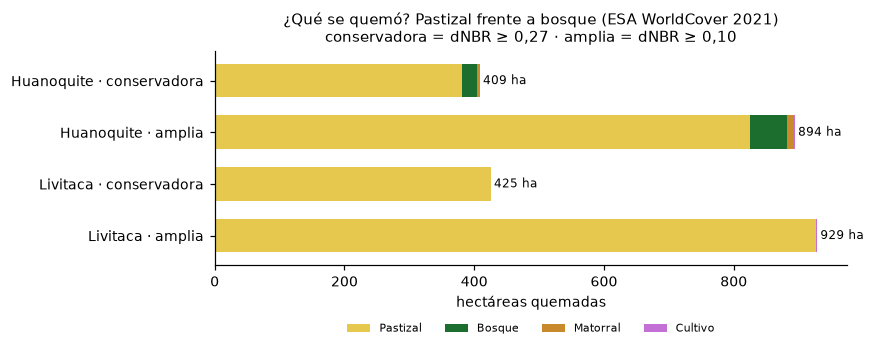

In [8]:
COLORES_WC = {"Pastizal": "#e6c84f", "Bosque": "#1b6e2d", "Matorral": "#c98a2b", "Cultivo": "#c46fd6",
              "Suelo desnudo": "#9c9c9c", "Urbano": "#d62728", "Agua": "#2a6fb5", "Humedal": "#0096a0"}
ha_barras = que_se_quemo.stack().unstack("cobertura").fillna(0)
ha_barras = ha_barras[[c for c in COLORES_WC if c in ha_barras.columns]]
ha_barras.index = [f"{i} · {c.split(' ')[0]}" for i, c in ha_barras.index]
fig, ax = plt.subplots(figsize=(8, 3.4))
ha_barras.iloc[::-1].plot.barh(stacked=True, ax=ax, color=COLORES_WC, width=0.65)
for i, total in enumerate(ha_barras.iloc[::-1].sum(axis=1)):
    ax.text(total + 5, i, f"{total:,.0f} ha", va="center", fontsize=8)
ax.set_xlabel("hectáreas quemadas"); ax.legend(frameon=False, fontsize=7.5, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.set_title("¿Qué se quemó? Pastizal frente a bosque (ESA WorldCover 2021)\n"
             "conservadora = dNBR ≥ 0,27 · amplia = dNBR ≥ 0,10", fontsize=9.5)
plt.tight_layout(); fig.savefig(FIG / "03_que_se_quemo.png", dpi=150); plt.show()

El mismo resultado en el mapa: cada píxel quemado pintado según lo que había **antes** del fuego.
Color intenso = quemado con dNBR ≥ 0,27; color pálido = solo en la cifra amplia (0,10 a 0,27).

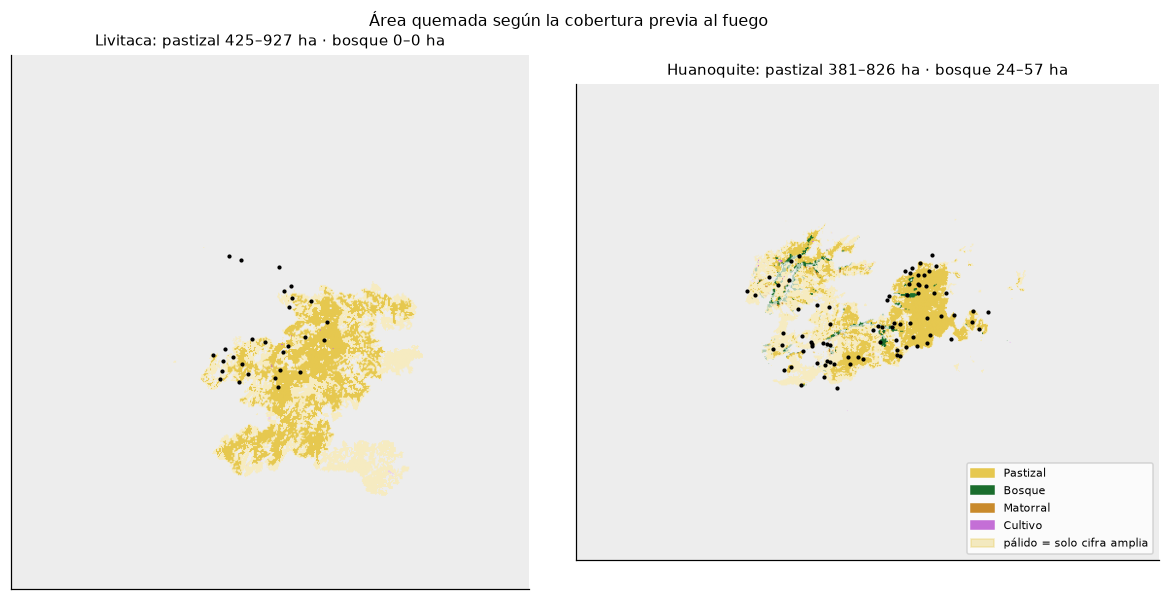

In [9]:
from matplotlib.colors import to_rgba
fig, ejes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (nombre, caso) in zip(ejes, CASOS.items()):
    clases = pd.Series(caso["wc"].values.ravel()).map(CLASES_WC).values.reshape(caso["wc"].shape)
    img = np.ones(clases.shape + (4,))
    img[..., :3] = 0.93
    for cobertura, color in COLORES_WC.items():
        es = clases == cobertura
        img[es & caso["zona_amplia"] & ~caso["zona"]] = to_rgba(color, 0.35)
        img[es & caso["zona"]] = to_rgba(color, 1)
    ext = [float(caso["ref"].x.min()), float(caso["ref"].x.max()), float(caso["ref"].y.min()), float(caso["ref"].y.max())]
    ax.imshow(img, extent=ext)
    foc = caso["focos"].to_crs(caso["ref"].rio.crs)
    ax.scatter(foc.geometry.x, foc.geometry.y, s=3, c="black", label="focos VIIRS")
    pas = que_se_quemo.loc[(nombre, "Pastizal")] if (nombre, "Pastizal") in que_se_quemo.index else pd.Series([0, 0])
    bos = que_se_quemo.loc[(nombre, "Bosque")] if (nombre, "Bosque") in que_se_quemo.index else pd.Series([0, 0])
    ax.set_title(f"{nombre}: pastizal {pas.iloc[0]:,.0f}–{pas.iloc[1]:,.0f} ha · bosque {bos.iloc[0]:,.0f}–{bos.iloc[1]:,.0f} ha",
                 fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([])
from matplotlib.patches import Patch
ejes[1].legend(handles=[Patch(color=COLORES_WC[c], label=c) for c in ("Pastizal", "Bosque", "Matorral", "Cultivo")]
               + [Patch(color=to_rgba("#e6c84f", 0.35), label="pálido = solo cifra amplia")],
               loc="lower right", fontsize=7.5, frameon=True)
fig.suptitle("Área quemada según la cobertura previa al fuego", fontsize=10.5)
plt.tight_layout(); fig.savefig(FIG / "03_mapa_cobertura_quemada.png", dpi=150); plt.show()

## Área quemada como polígono

Convertimos los píxeles quemados en polígonos para los cruces con personas y viviendas.

In [10]:
from rasterio import features
from shapely.geometry import shape

for nombre, caso in CASOS.items():
    quemado = caso["zona"].astype("uint8")
    geoms = [shape(g) for g, v in features.shapes(quemado, mask=quemado == 1, transform=caso["ref"].rio.transform())]
    caso["area_quemada"] = gpd.GeoSeries(geoms, crs=caso["ref"].rio.crs).union_all()
    quemado = caso["zona_amplia"].astype("uint8")
    geoms = [shape(g) for g, v in features.shapes(quemado, mask=quemado == 1, transform=caso["ref"].rio.transform())]
    caso["area_quemada_amplia"] = gpd.GeoSeries(geoms, crs=caso["ref"].rio.crs).union_all()
filas_geo = []
for nombre, caso in CASOS.items():
    for cifra, clave, ha in (("conservadora", "area_quemada", caso["quemado_ha"]),
                             ("amplia", "area_quemada_amplia", caso["quemado_amplio_ha"])):
        filas_geo.append({"incendio": nombre, "cifra": cifra, "ha": ha,
                          "geometry": gpd.GeoSeries([caso[clave]], crs=caso["ref"].rio.crs).to_crs(4326).iloc[0]})
gpd.GeoDataFrame(filas_geo, crs=4326).to_file(PROC / "area_quemada_cusco.gpkg", driver="GPKG")
print("guardado:", PROC / "area_quemada_cusco.gpkg")

guardado: /Users/greicyrc/Documents/GitHub/grey_diplomado/tarea_raster/datos/procesados/area_quemada_cusco.gpkg


## Resumen para el tablero

Fechas, nubes, hectáreas y sensibilidad de cada incendio, en un JSON que lee el notebook 5.

In [11]:
import json
resumen = {}
for nombre, caso in CASOS.items():
    nubes = {}
    for it in caso["items_antes"] + [caso["item_despues"]]:
        scl = recortar(it, "SCL", caso["caja"])
        nubes[f"{it.datetime:%Y-%m-%d}"] = round(float(np.isin(scl, [3, 8, 9, 10]).sum() / (scl > 0).sum()) * 100, 1)
    fila = incendios.loc[caso["incendio"]]
    resumen[nombre] = {
        "distrito": fila.distrito, "provincia": fila.provincia, "departamento": fila.departamento,
        "fuego_viirs": [fila.inicio[:10], fila.ultimo[:10]], "focos": int(fila.focos), "huella_viirs_ha": float(fila.huella_ha),
        "imagenes_antes": caso["antes"], "imagen_despues": caso["despues"], "nubes_pct": nubes,
        "escenas": [it.id for it in caso["items_antes"] + [caso["item_despues"]]],
        "ha_conservadora": round(float(caso["quemado_ha"]), 1), "ha_amplia": round(float(caso["quemado_amplio_ha"]), 1),
        "severidad_ha": caso["severidad_ha"].round(1).to_dict(),
        "sensibilidad_ha": sensibilidad[nombre].to_dict(),
    }
(PROC / "dnbr_resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1))
print(json.dumps(resumen["Livitaca"], ensure_ascii=False)[:400])

{"distrito": "LIVITACA", "provincia": "CHUMBIVILCAS", "departamento": "CUSCO", "fuego_viirs": ["2026-10-15", "2026-10-15"], "focos": 28, "huella_viirs_ha": 267.1875, "imagenes_antes": ["2026-10-07"], "imagen_despues": "2026-10-17", "nubes_pct": {"2026-10-07": 0.0, "2026-10-17": 0.0}, "escenas": ["S2A_MSIL2A_20261007T145941_R039_T19LBE_20261007T224605", "S2A_MSIL2A_20261017T145731_R039_T19LBE_20261
